In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240220_TempoSO4_W3.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240220_TempoSO4_W3_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating
d3 = find_file("240220_TempoSO4_W3_run3.DSC", exp_type="francklab_esr/romana") # heating 3 subsequently --not used
d4 = find_file("240220_TempoSO4_W3_run4.DSC", exp_type="francklab_esr/romana") # cooling 4 subsequently --not used

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (10, 'Temperature'), (10, 'harmonic')]

In [5]:
d3.shape

[(1024, '$B_0$'), (7, 'Temperature'), (10, 'harmonic')]

In [6]:
d4.shape

[(1024, '$B_0$'), (7, 'Temperature'), (10, 'harmonic')]

In [7]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [8]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (10, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [9]:
d3.chunk_auto("harmonic", "harmonic")
d3.shape

[(1024, '$B_0$'), (7, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [10]:
d4.chunk_auto("harmonic", "harmonic")
d4.shape

[(1024, '$B_0$'), (7, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling')

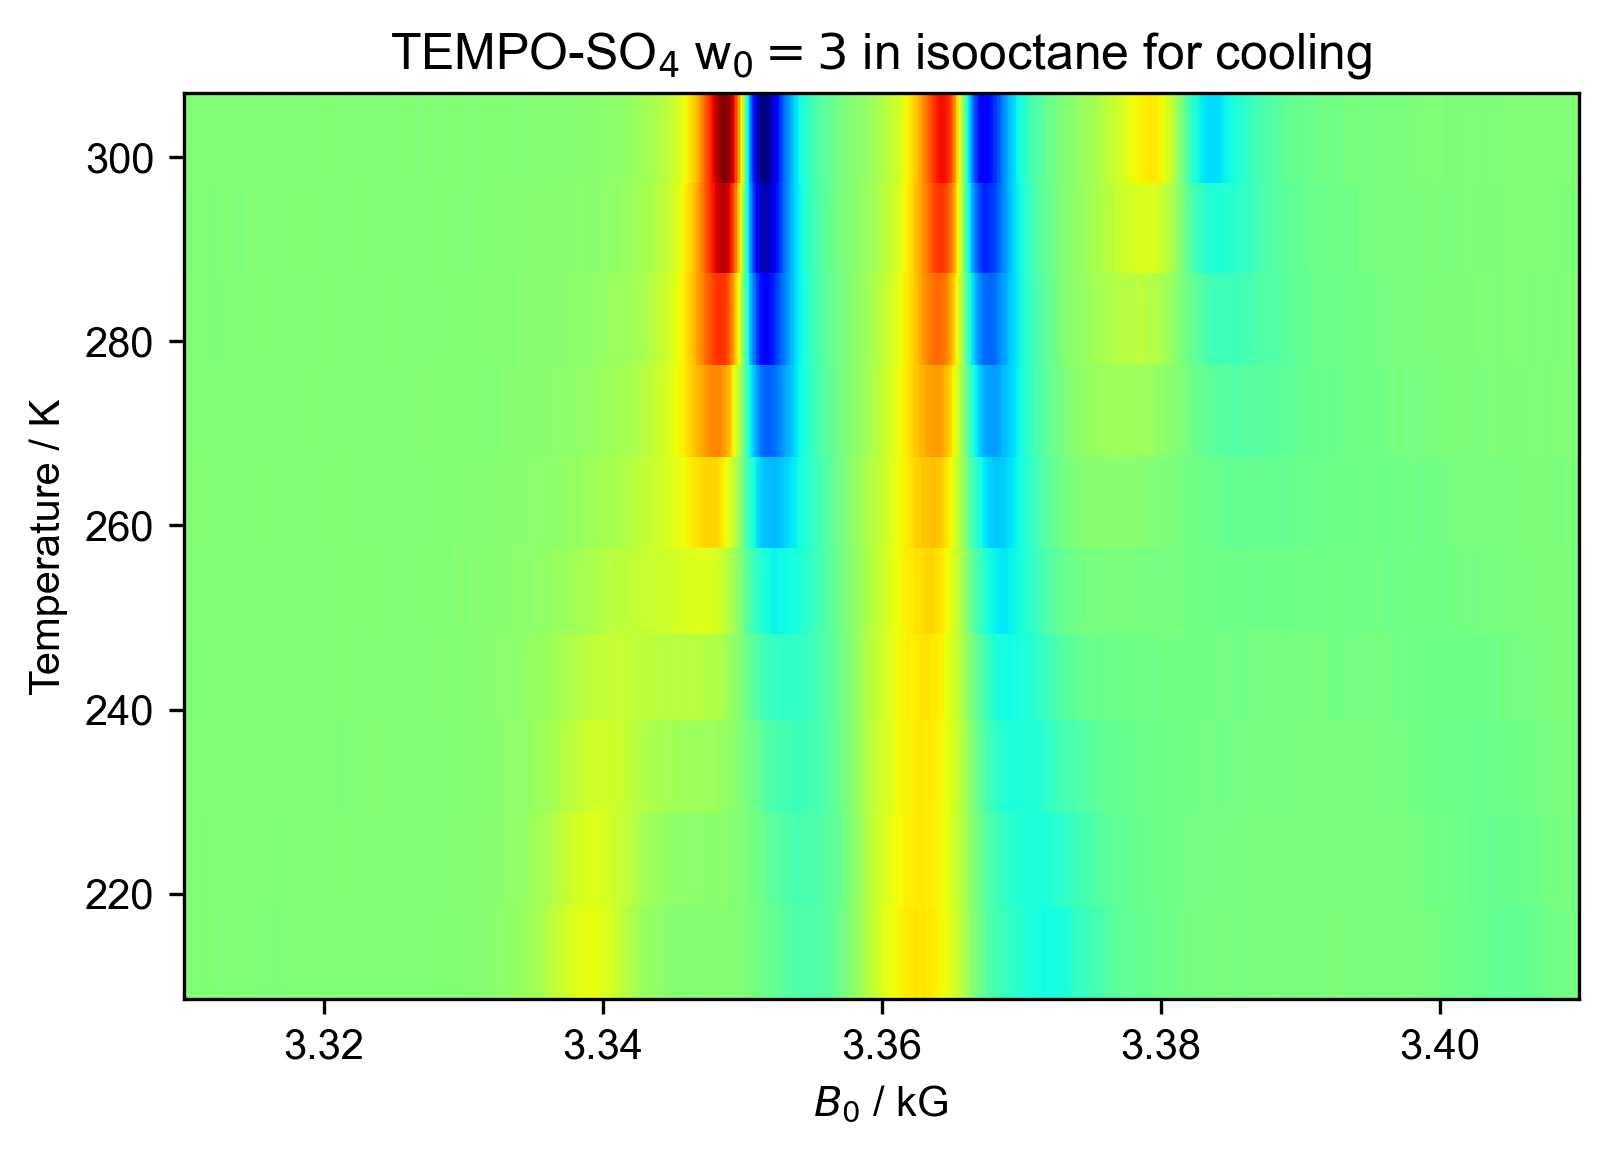

In [11]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in isooctane for heating')

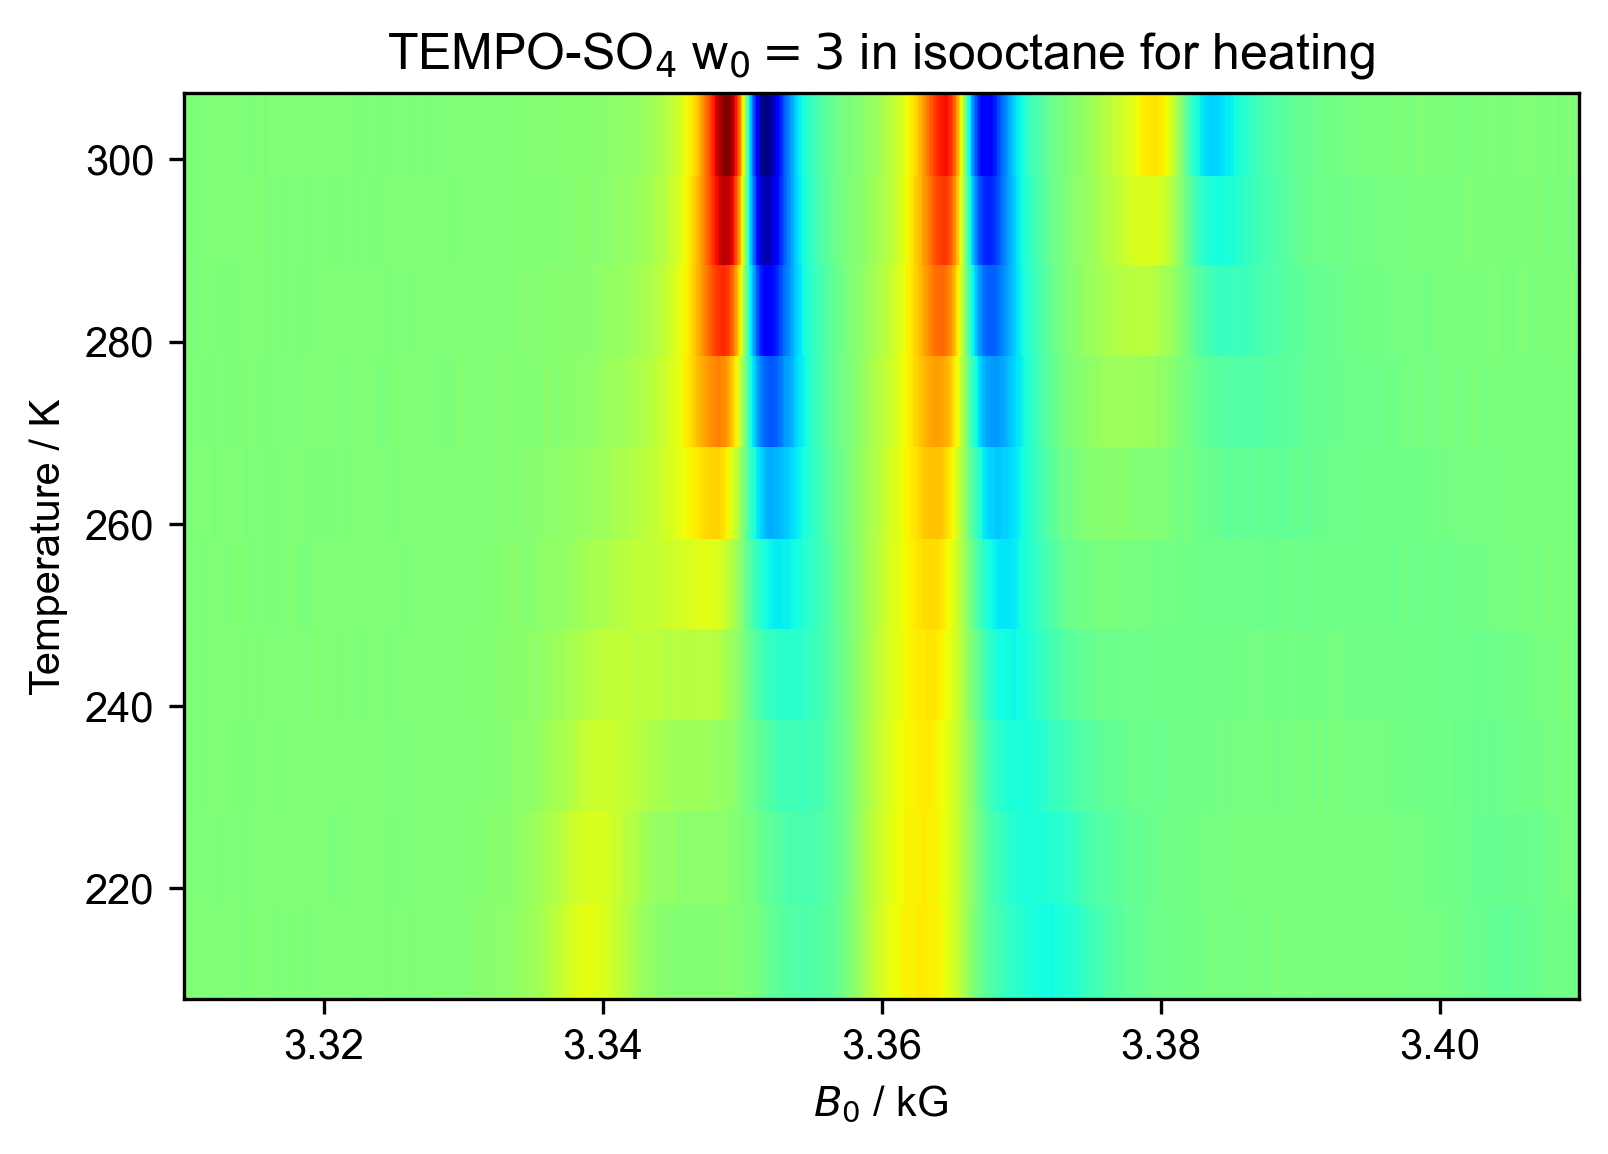

In [12]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in isooctane for heating")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling')

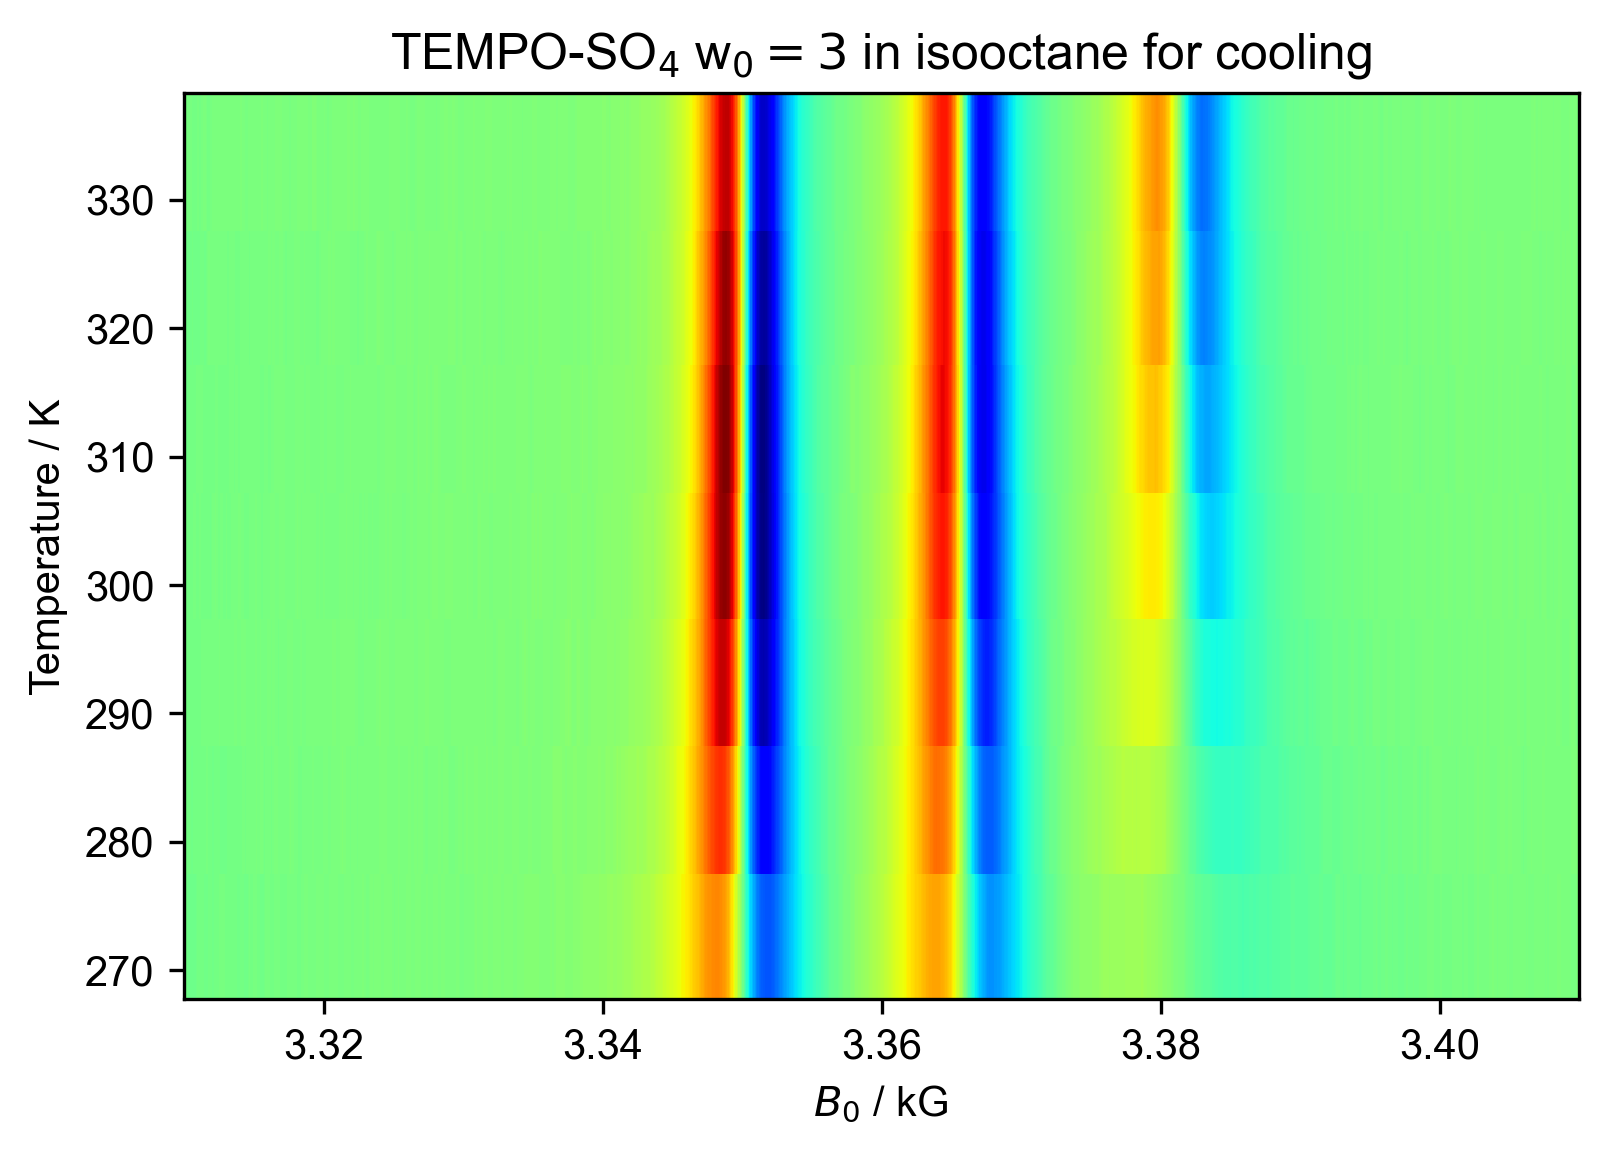

In [13]:
figure(dpi=300)
d4 = d4["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d4.sort('Temperature')
d4.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling")

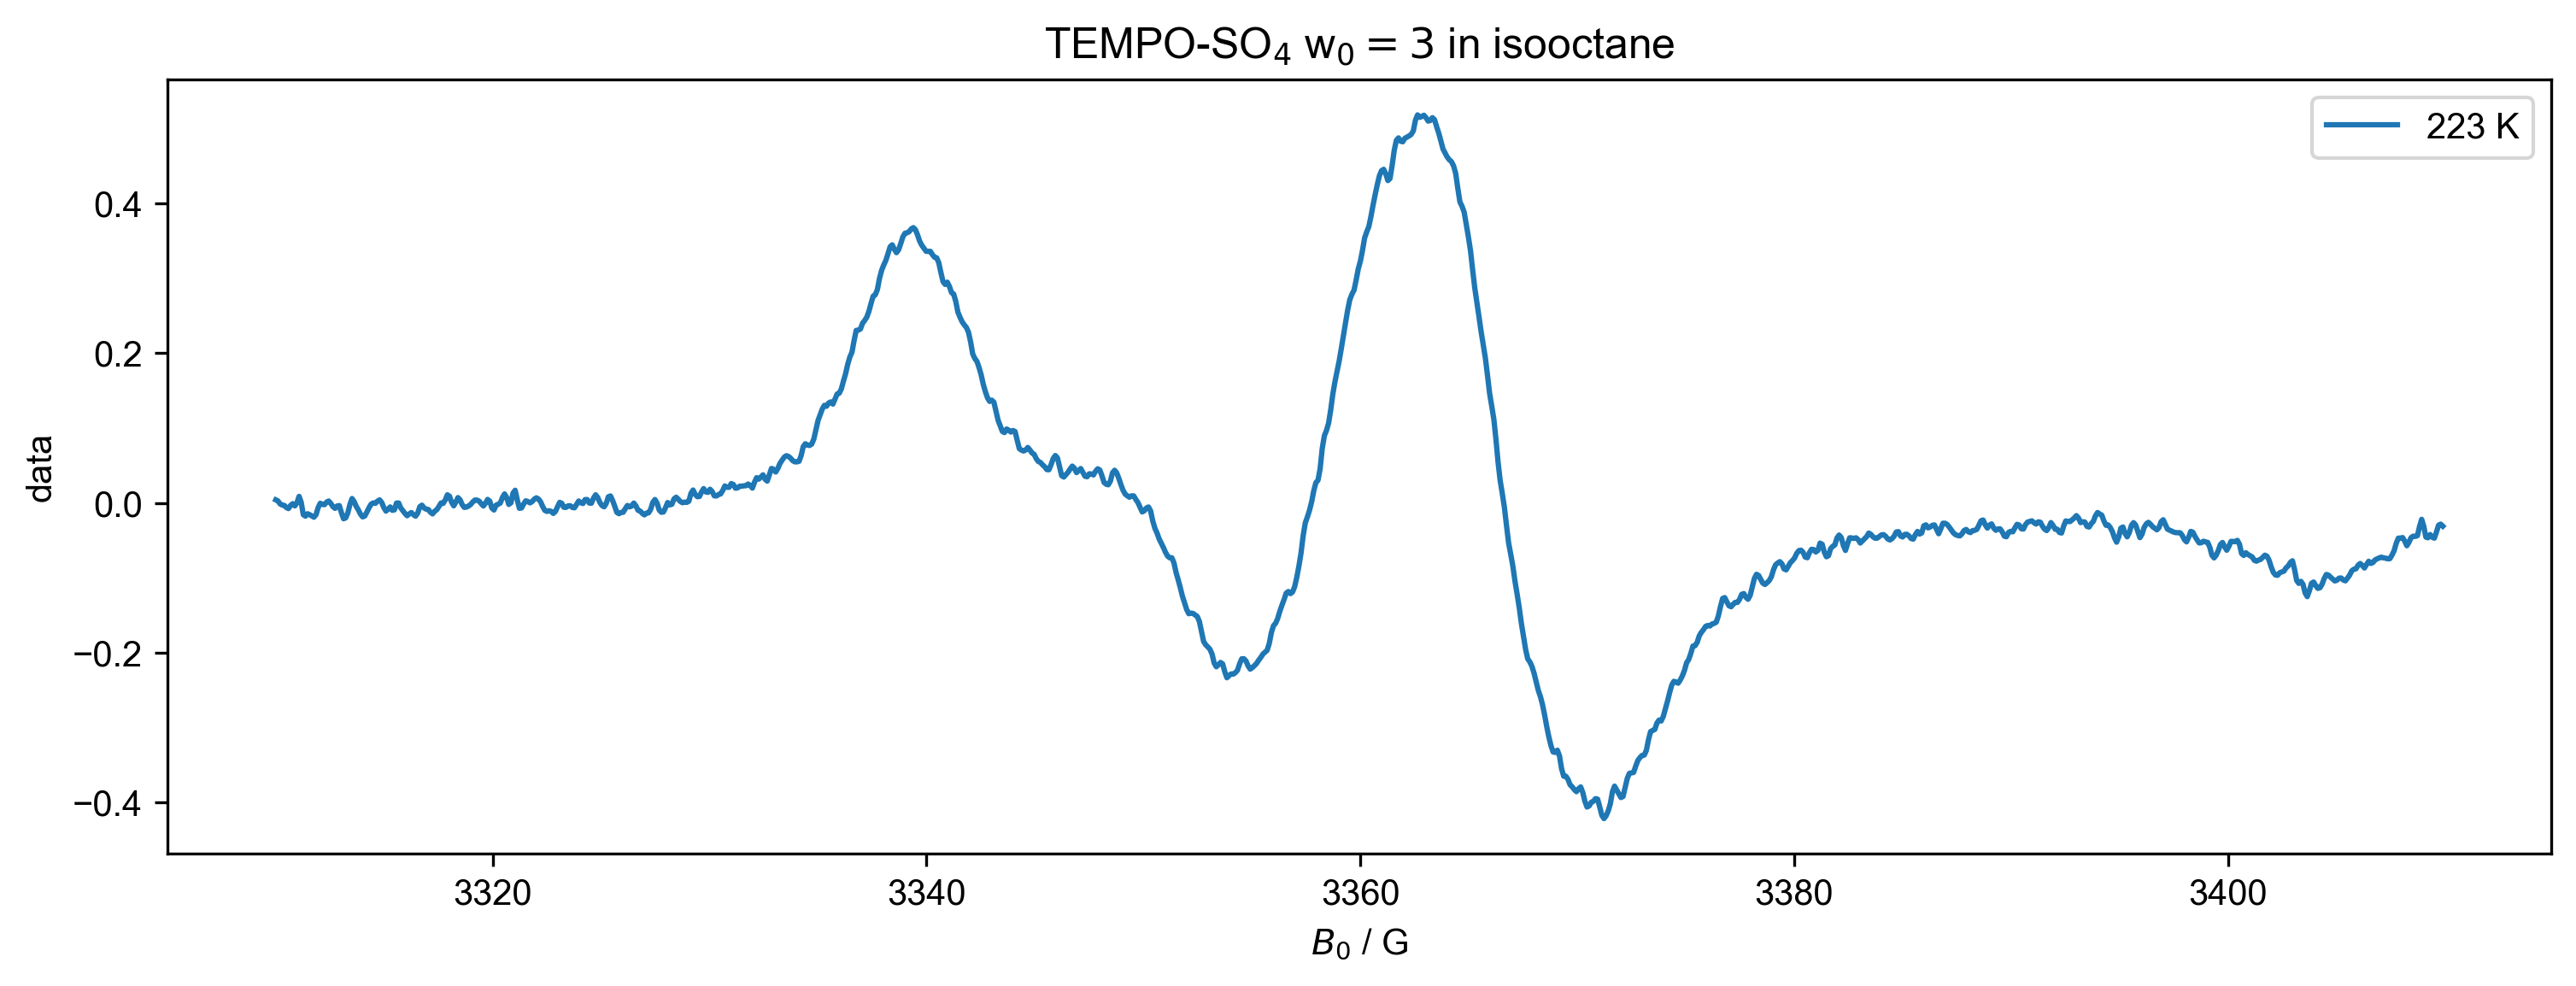

In [14]:
# SDE
figure(dpi=300, figsize=(12,4))
plot(d1["Temperature":223], label="223 K")
title("TEMPO-SO$_4$ w$_0= 3$ in isooctane")
legend()

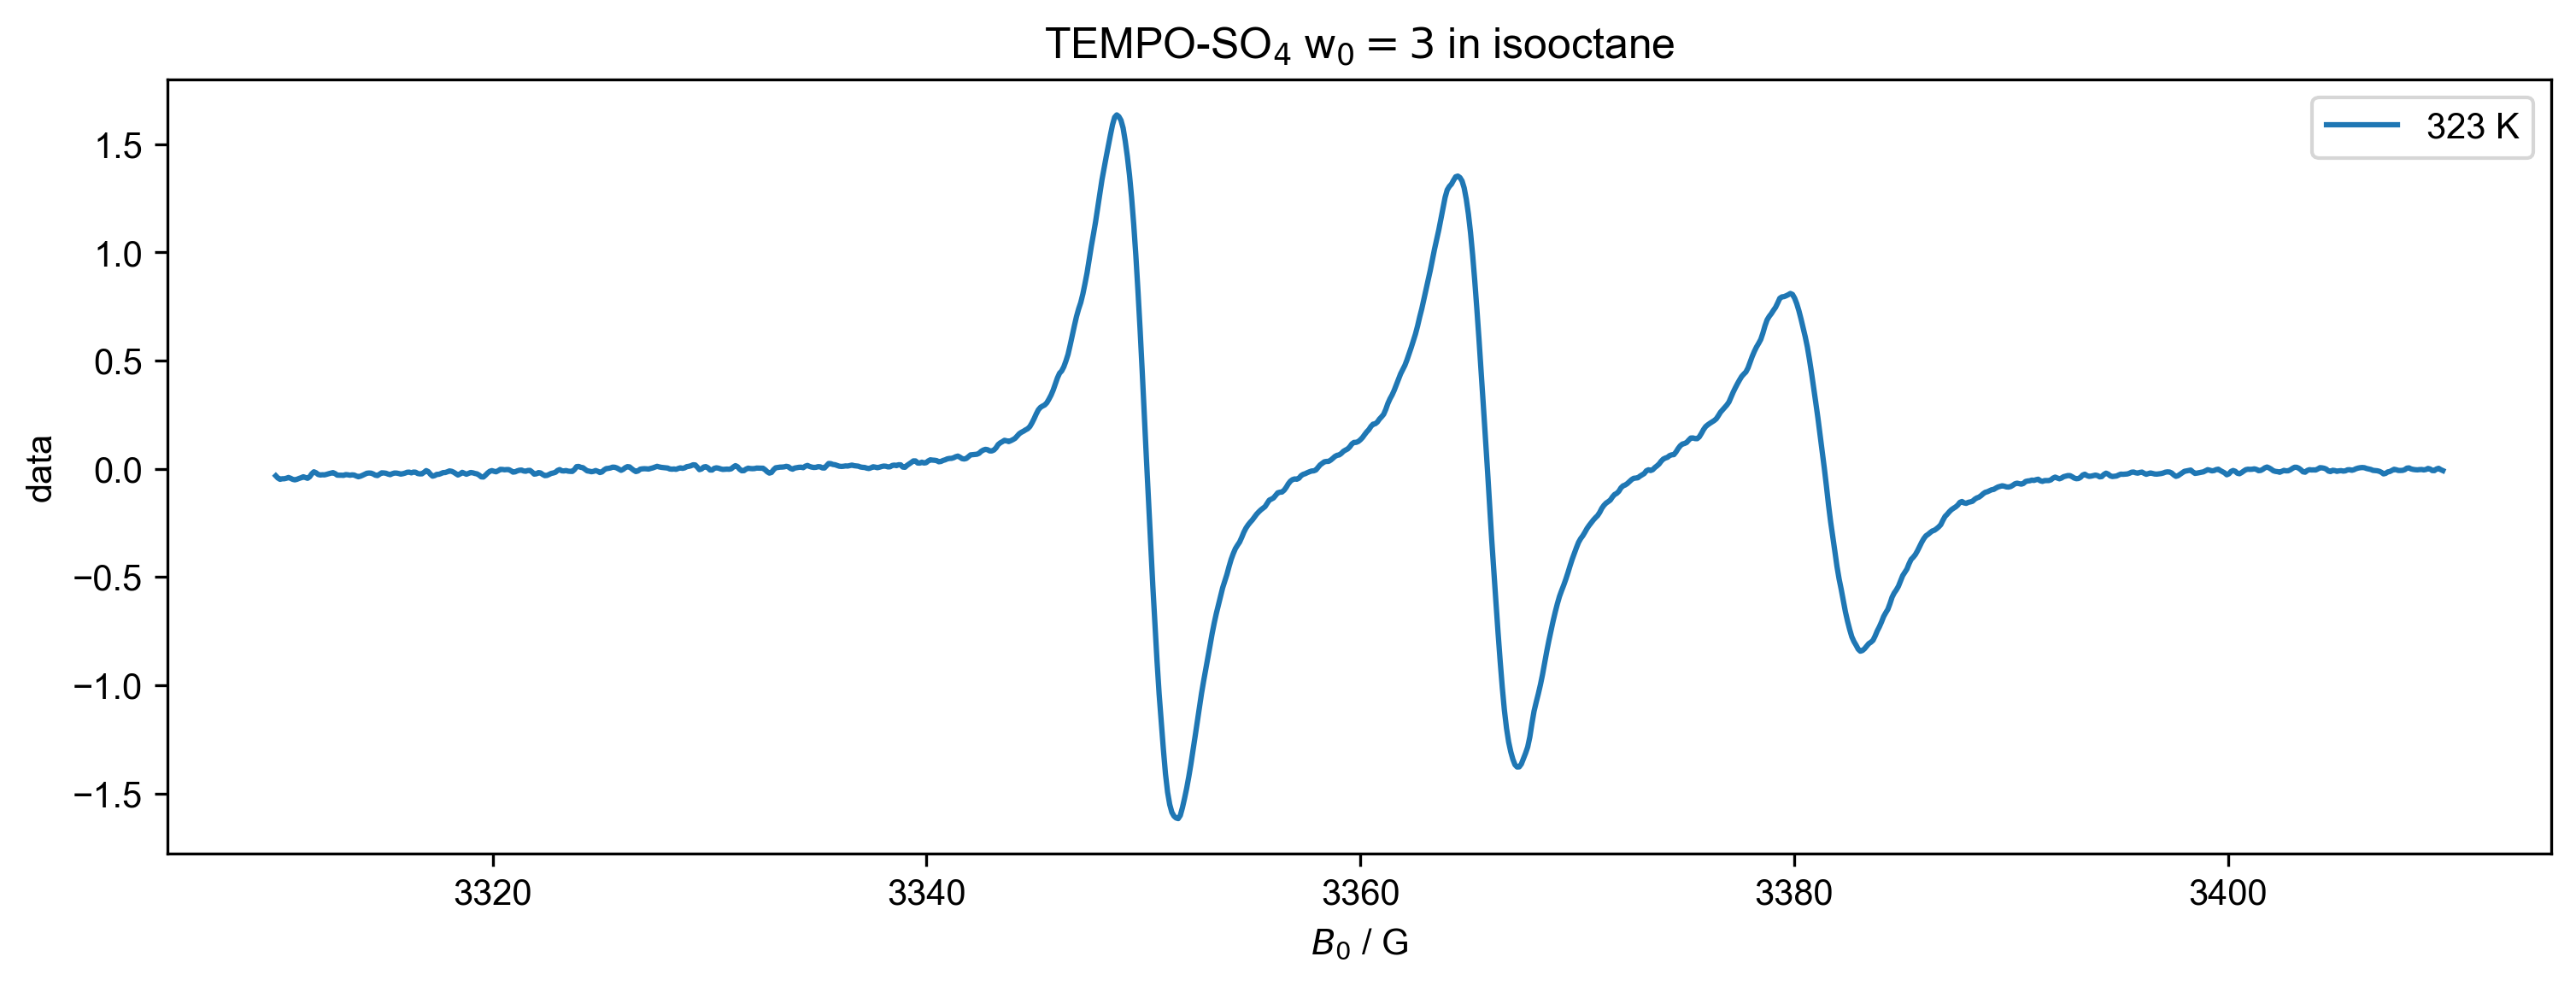

In [15]:
# SDE
# figure(dpi=300, figsize=(6,4))
# d4 = d4["harmonic", 0]["phase", 0]
# d4.sort('Temperature')
# d4.reorder("Temperature").pcolor()
figure(dpi=300, figsize=(12,4))
plot(d4["Temperature":323], label="323 K")
title("TEMPO-SO$_4$ w$_0= 3$ in isooctane")
legend()

From this, I learn that
it's easiest to show the 1D plots above and below the transition

RS: I'm plotting d1 and d2 only

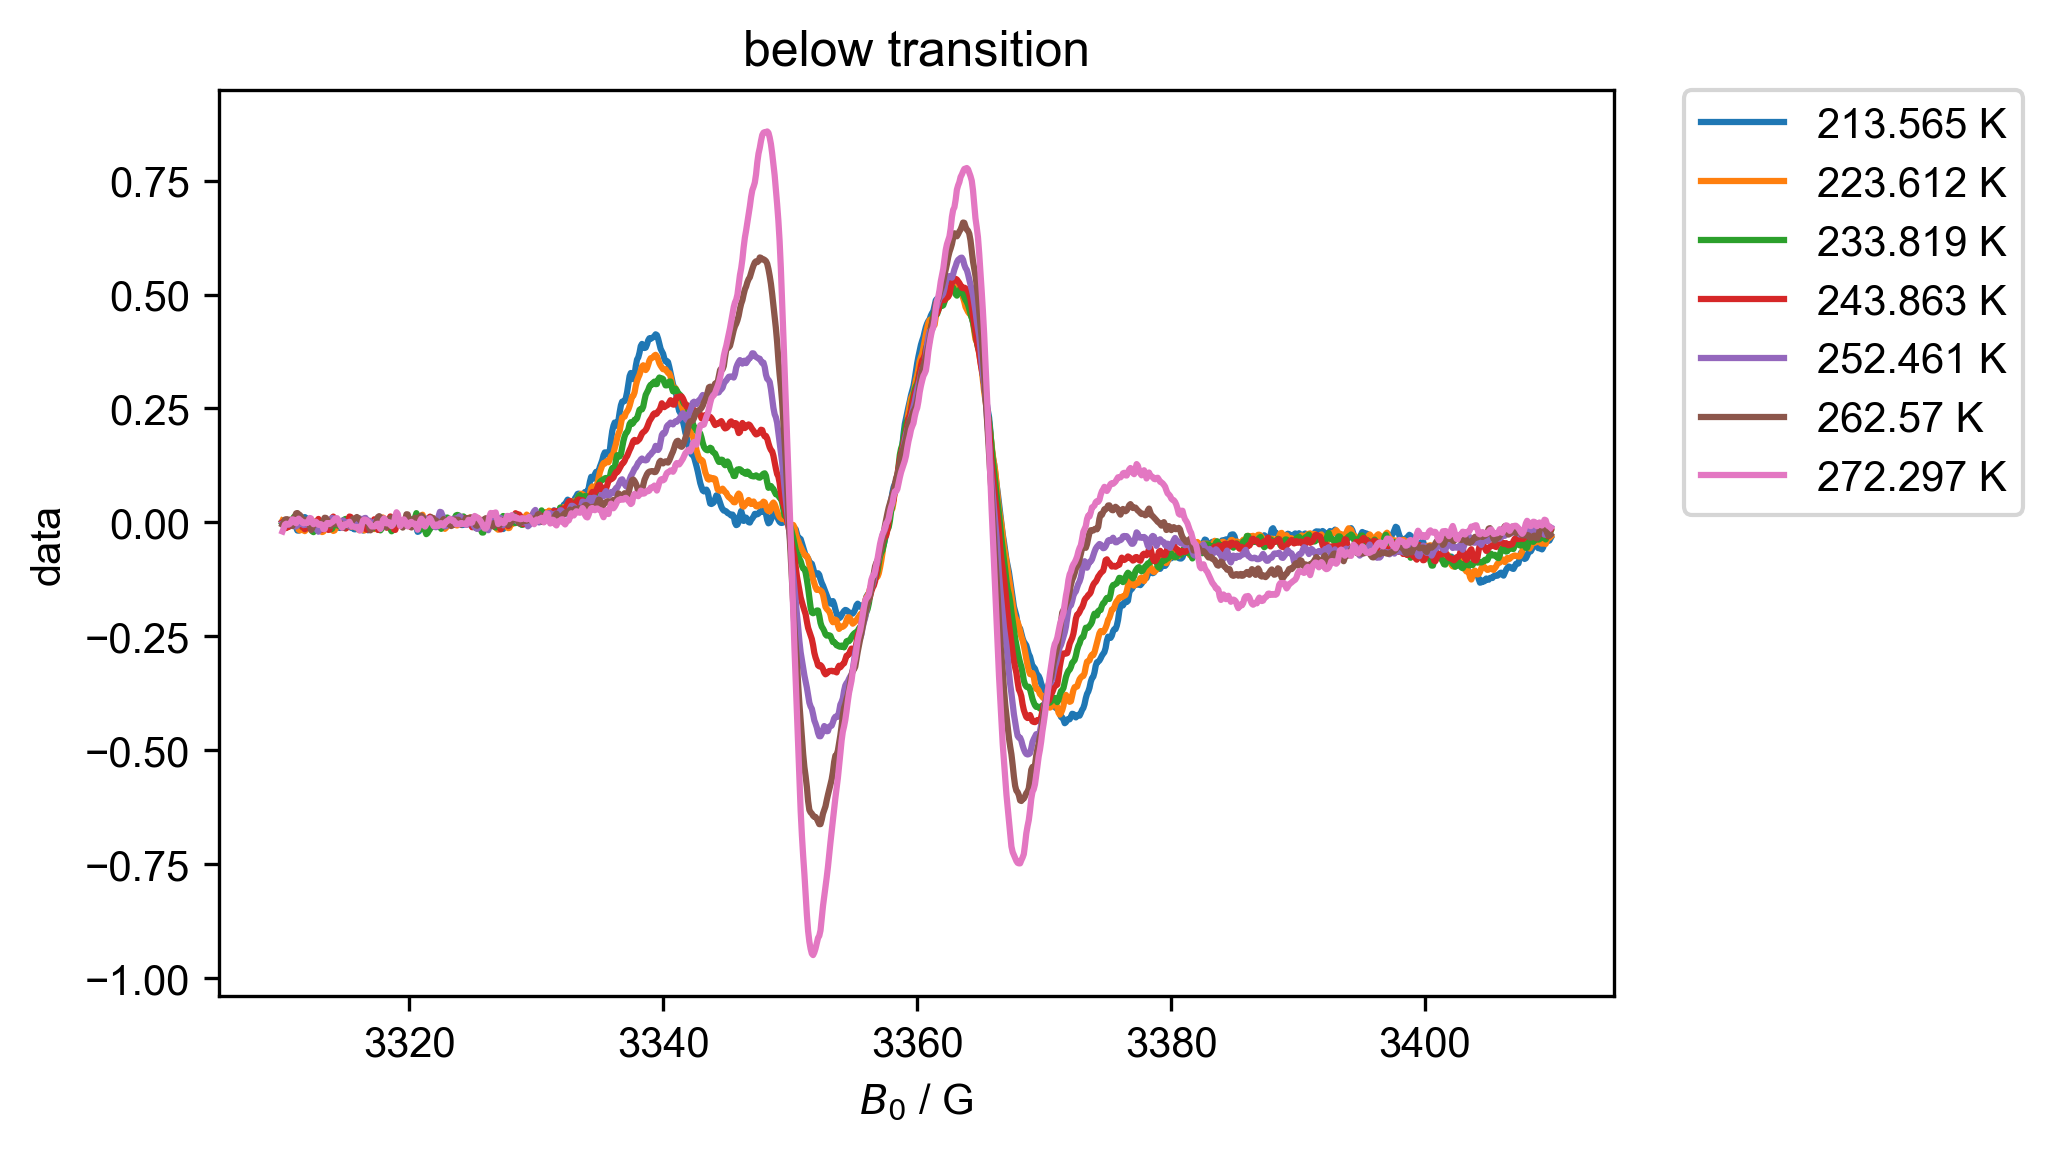

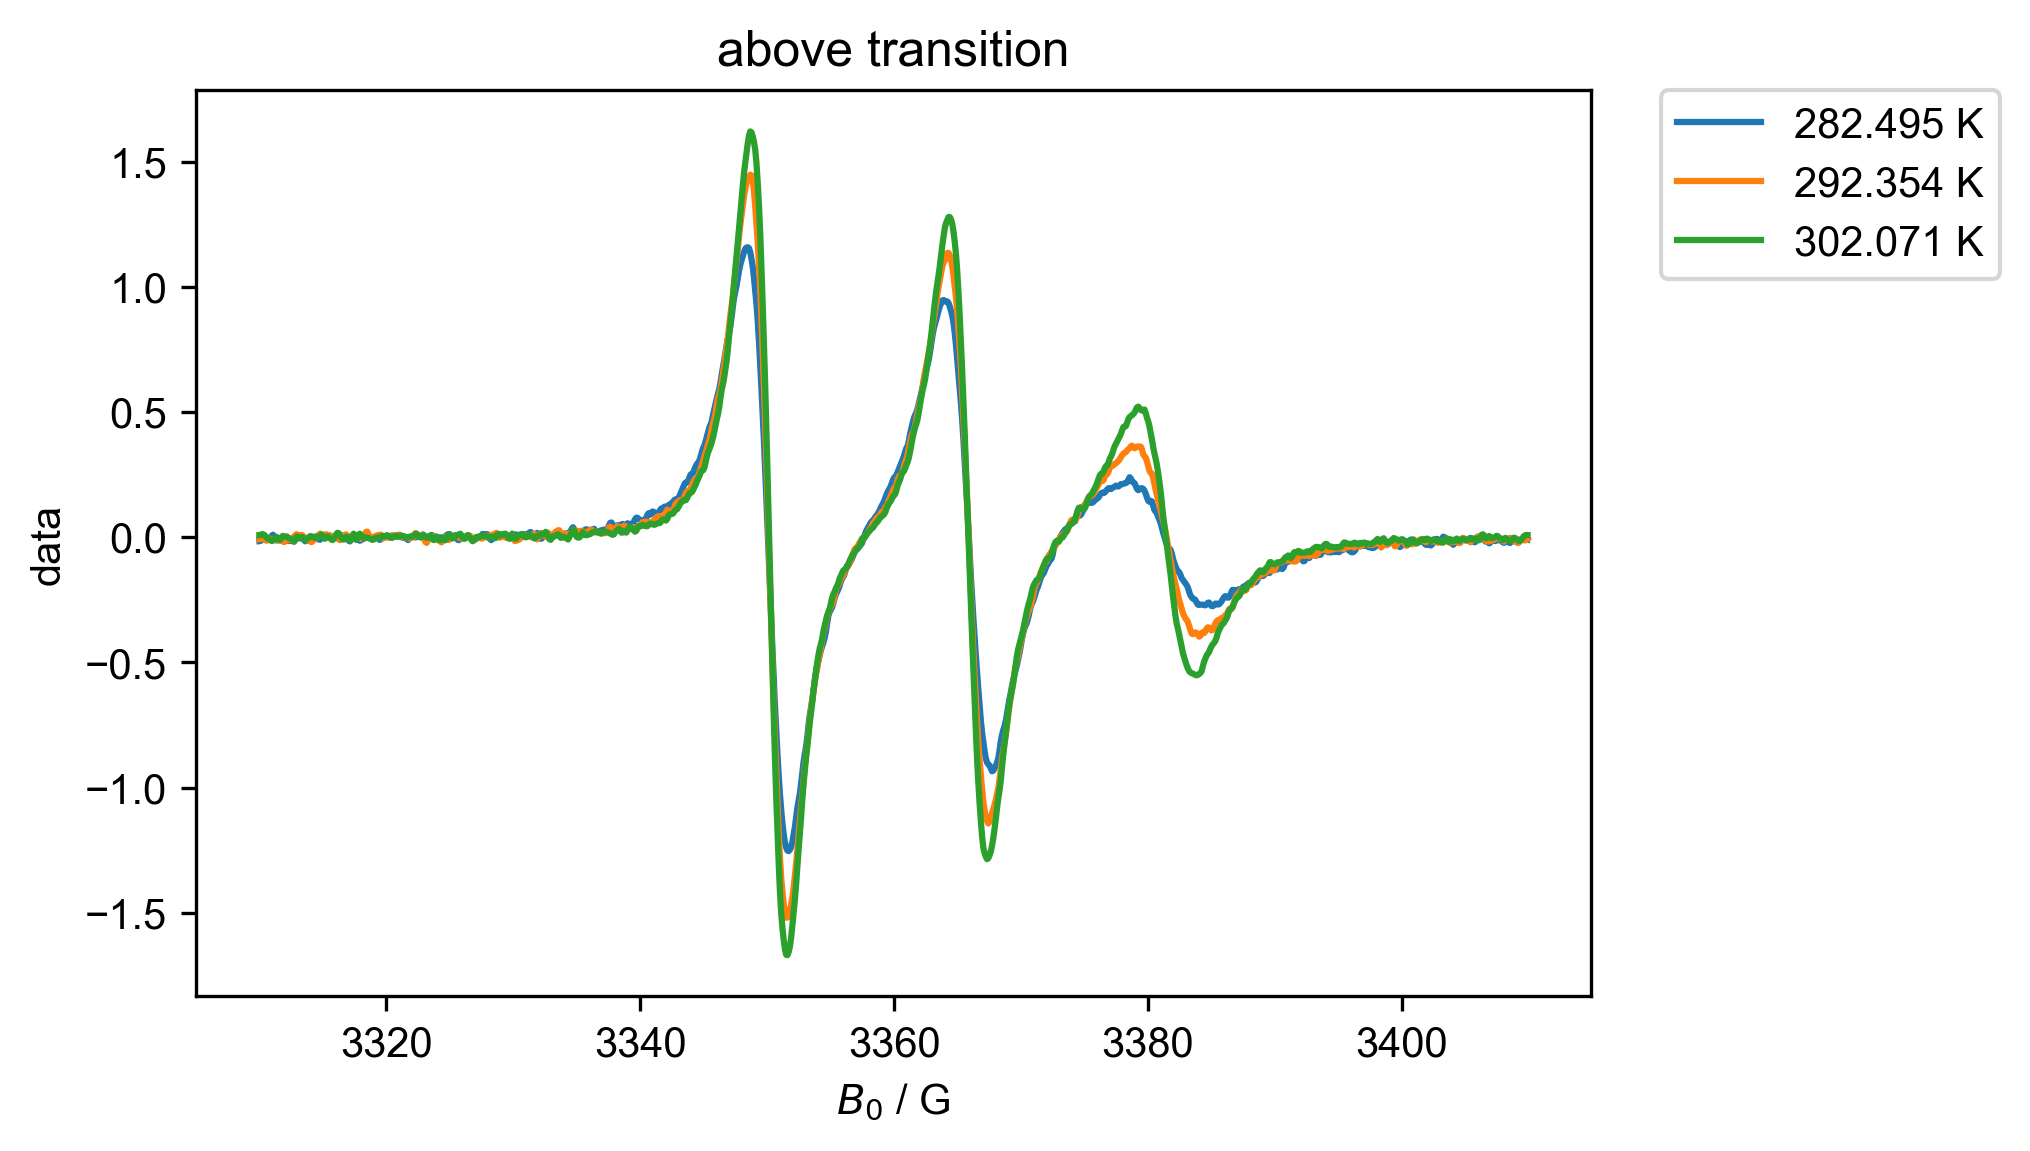

In [16]:
#cooling
for this_label, temp_range in [
    ("below transition", (None, 280)),
    ("above transition", (280, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

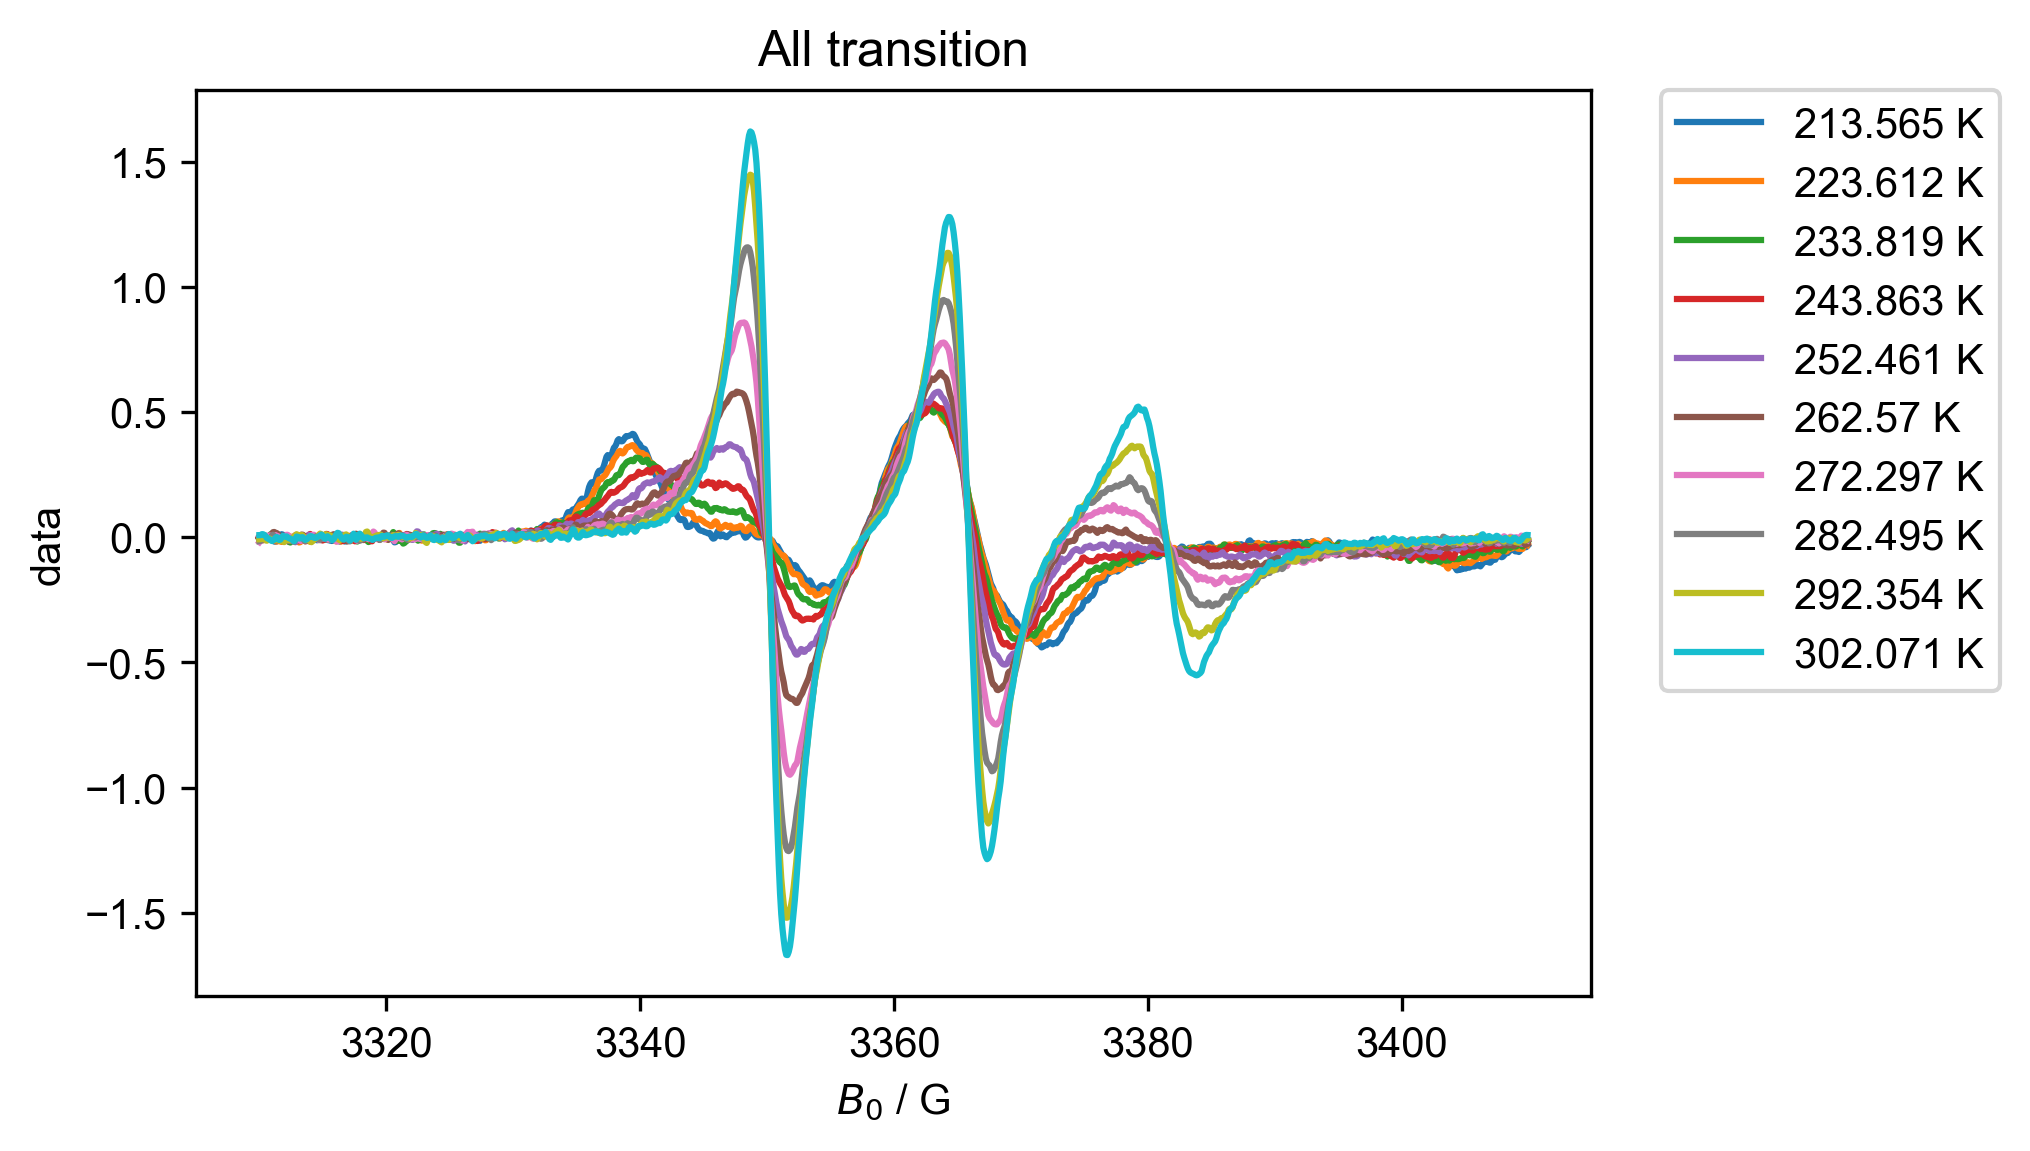

In [17]:
#cooling same plot
for this_label, temp_range in [
    ("All transition", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

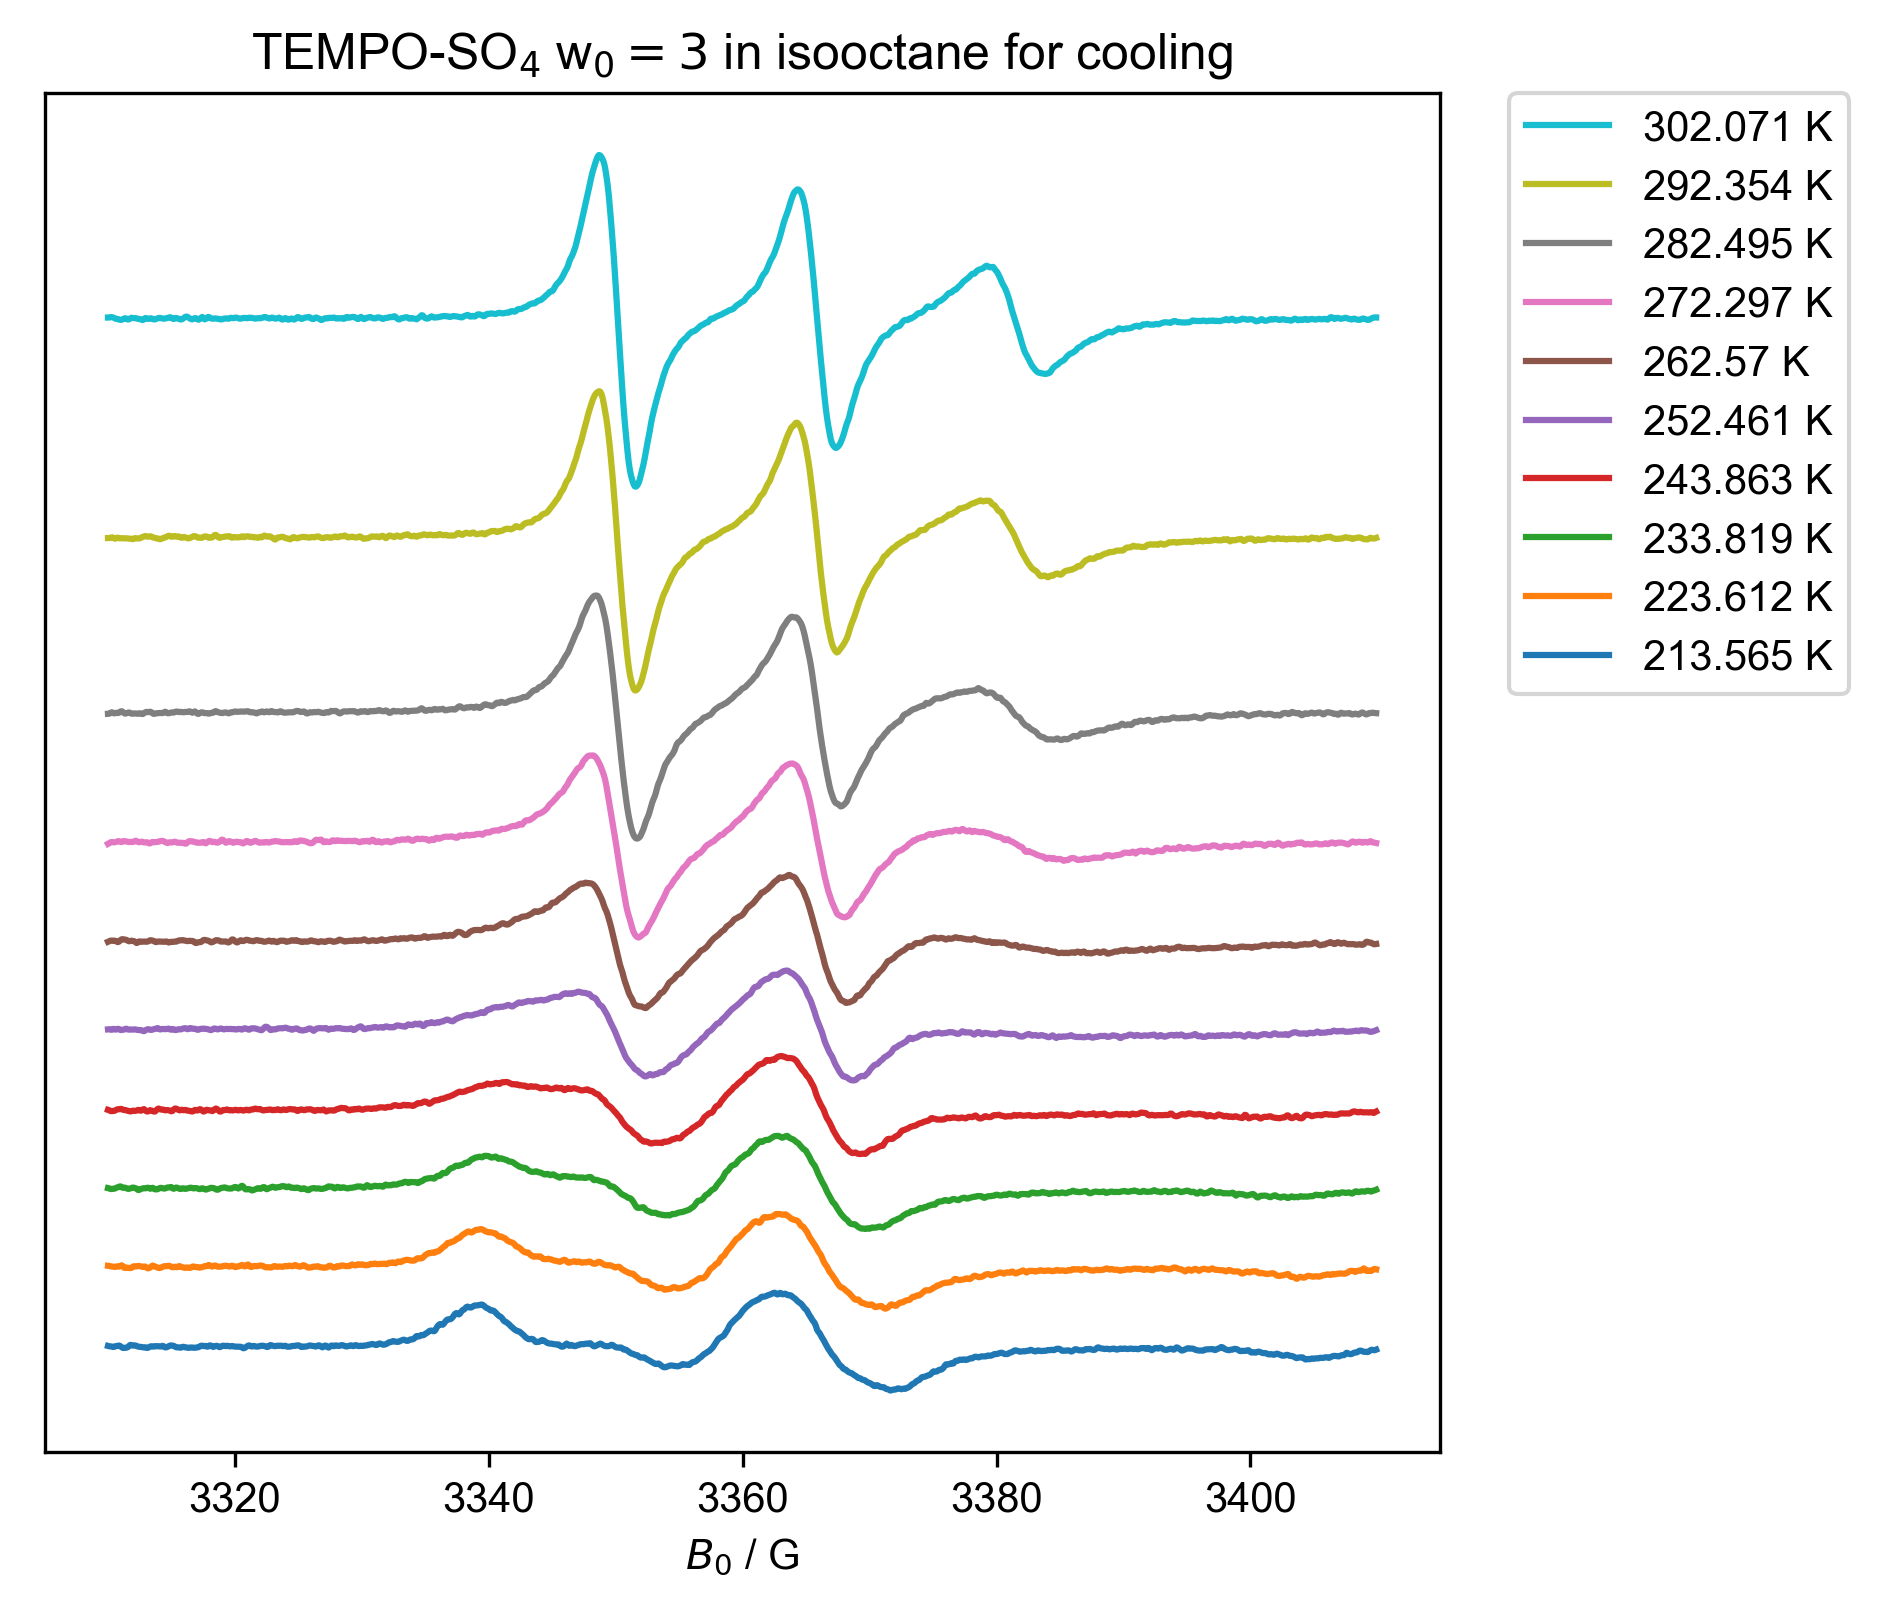

In [15]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

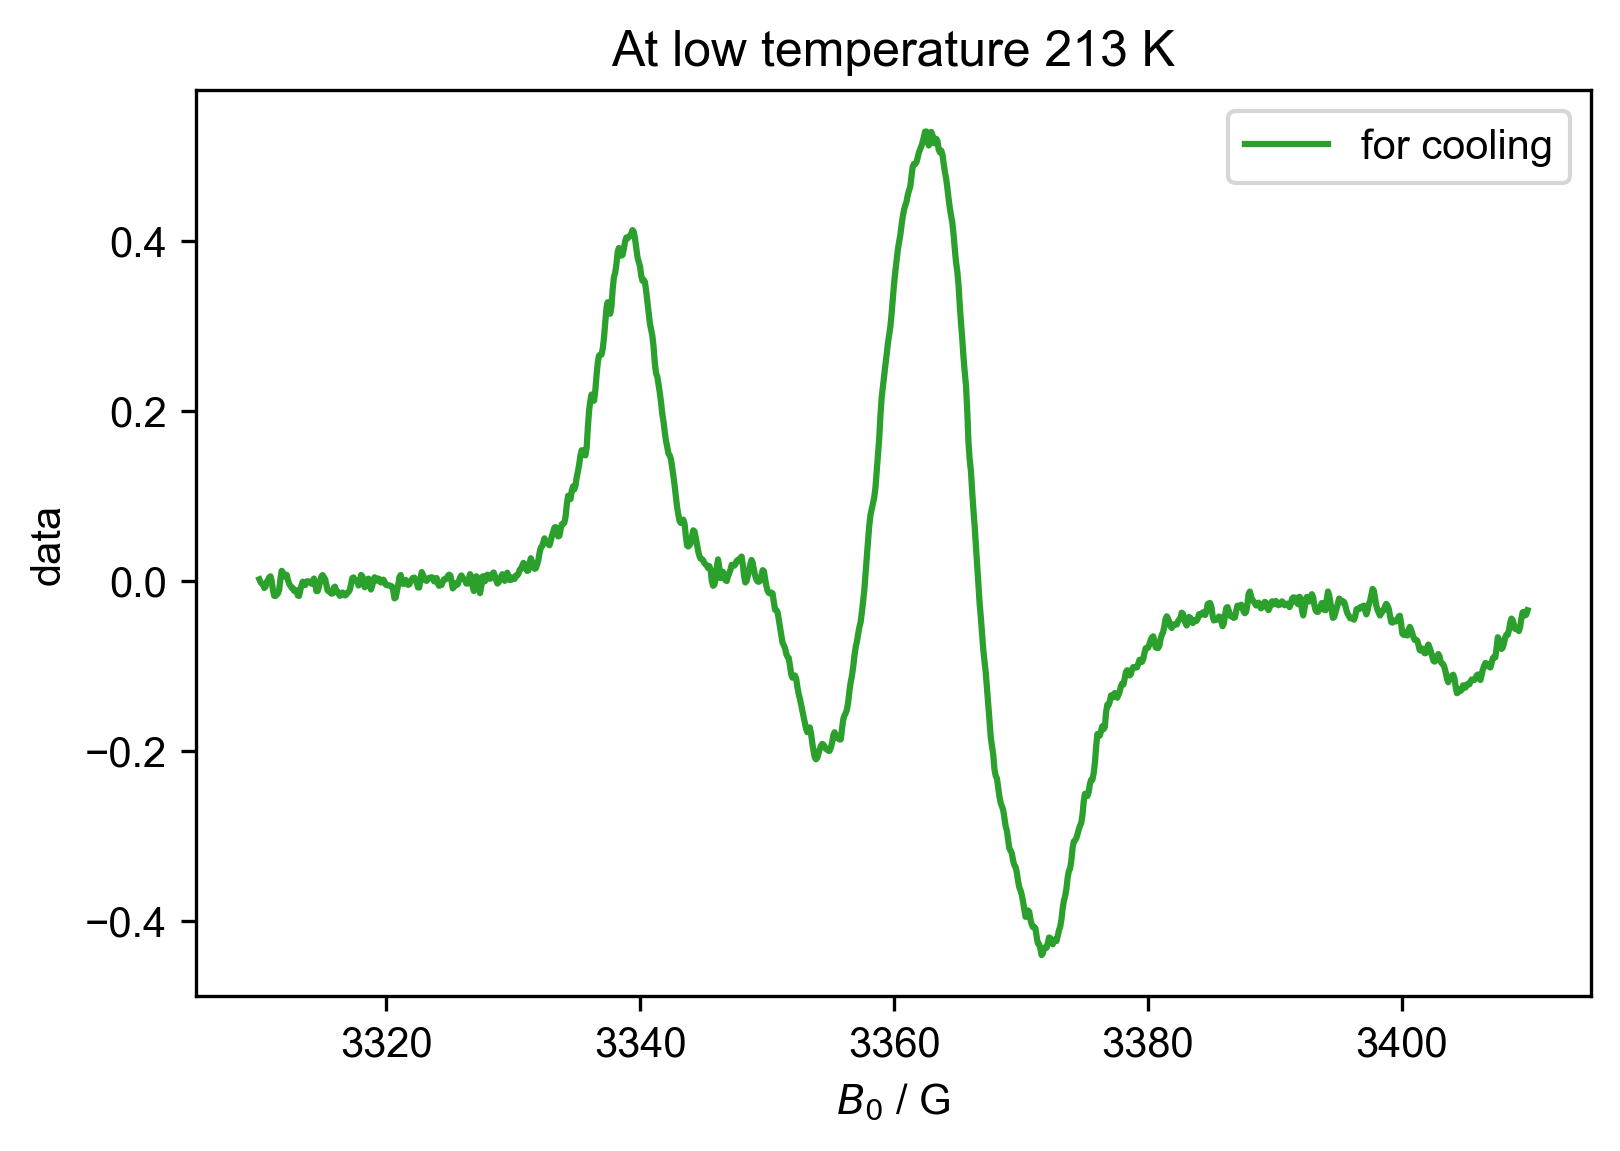

In [24]:
#near room temperature
#print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":213], label="for cooling", color="#2ca02c")
# plot(d2["Temperature":213], label="after cooling and heating")
title("At low temperature 213 K")
legend()

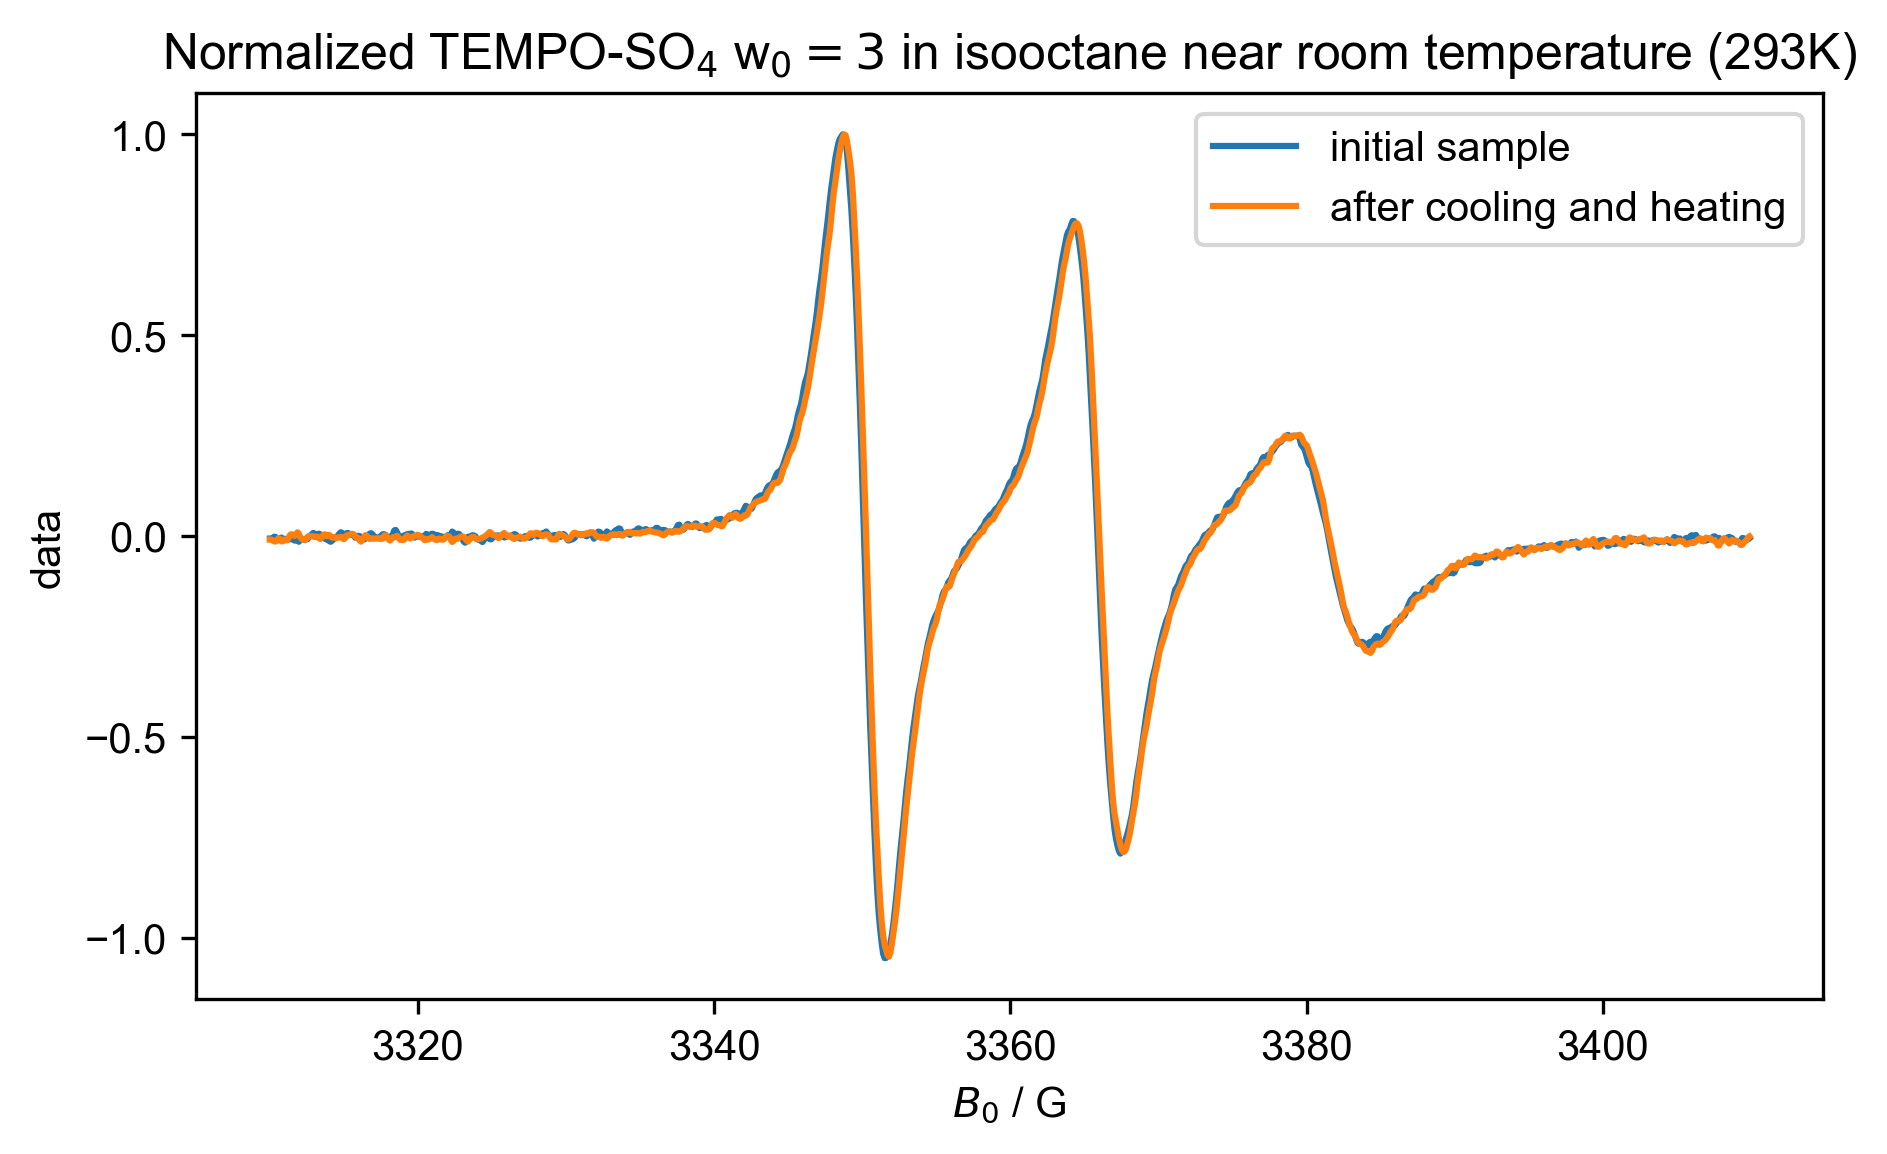

In [20]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "initial sample")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 3$ in isooctane near room temperature (293K)")
legend()

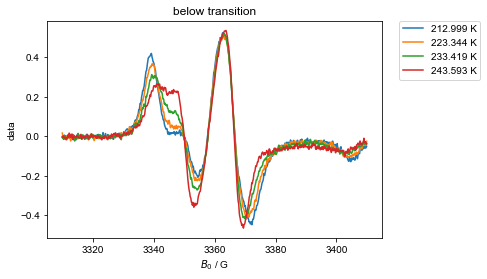

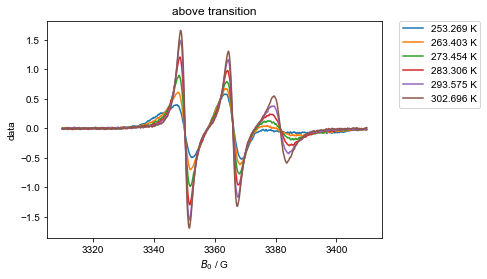

In [21]:
#heating run2
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

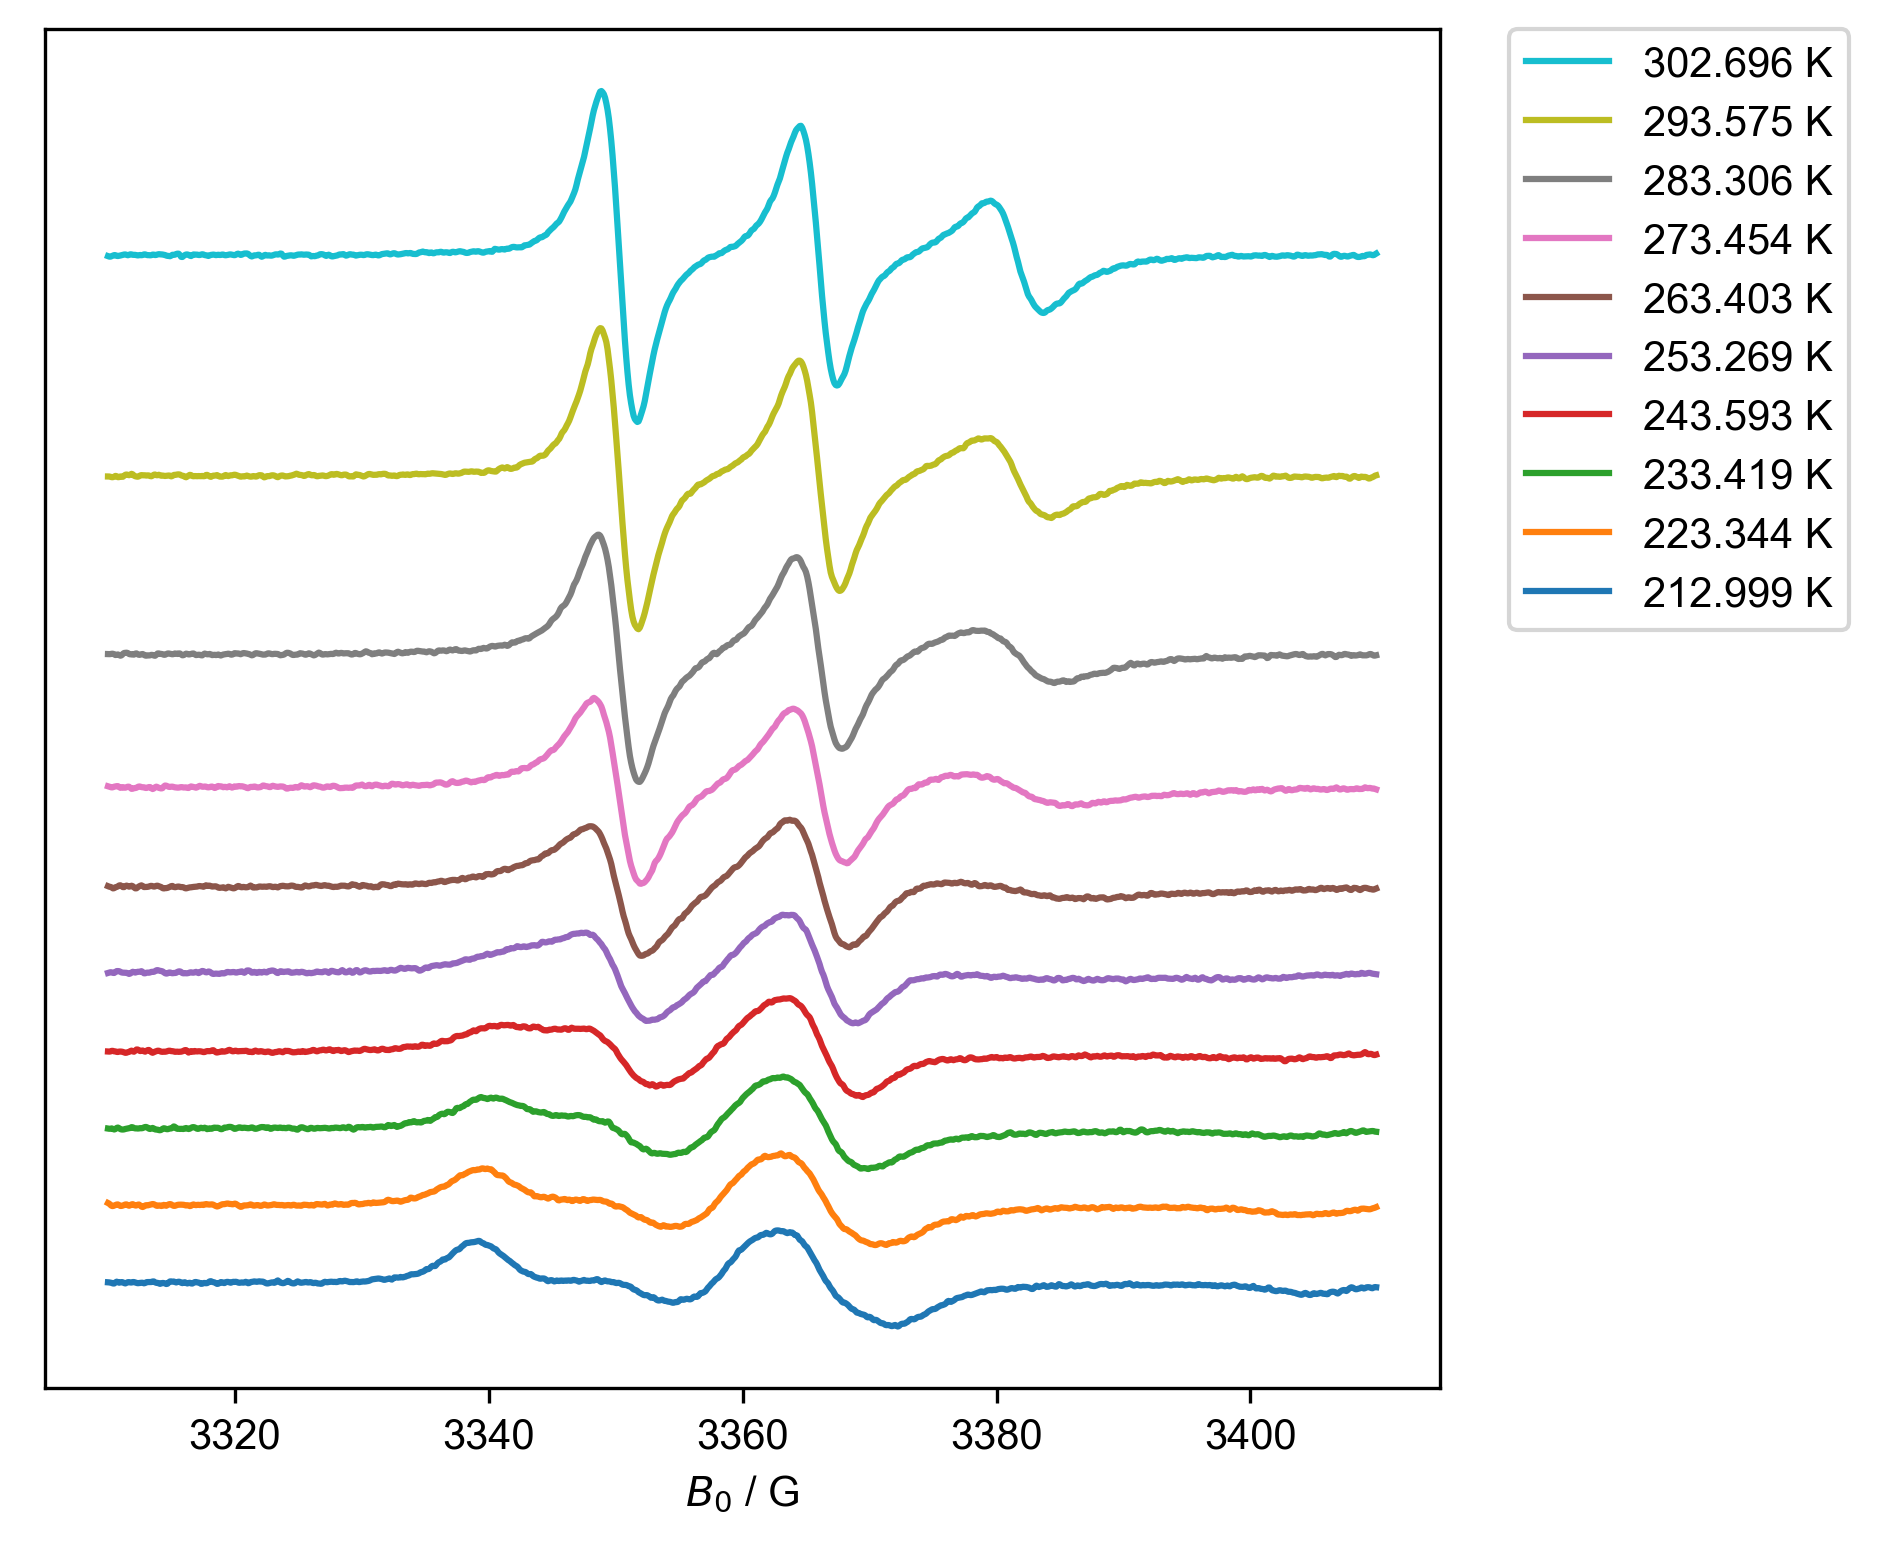

In [22]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

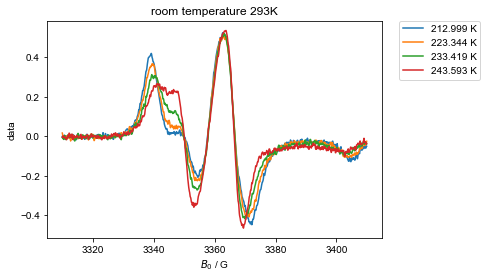

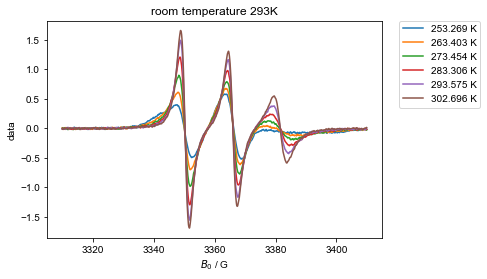

In [23]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title("room temperature 293K")
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()